Random Forest uses many decision trees to make better predictions.

Advamtages of Random Forest:
1. High Accuracy
2. Works with Large Dataset
3. Handle Missing Values
4. Reduces Overfitting

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings

warnings.filterwarnings('ignore')

In [5]:
titanic_data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/titanic.csv')

In [7]:
titanic_data.tail(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [10]:
titanic_data = titanic_data.dropna(subset=['Survived'])
titanic_data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [11]:
X = titanic_data[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']]
y = titanic_data['Survived']

X['Sex'] = X['Sex'].map({'female': 0, 'male': 1})

In [12]:
X['Age'] = X['Age'].fillna(X['Age'].median())

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X ,y, test_size=0.2, random_state=42)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)
y_pred = rf_classifier.predict(X_test)

In [26]:
accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:2f}")
print("\nClassification Report:\n", classification_rep)

Accuracy: 0.798883

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [24]:
sample = X_test.iloc[0:1]
prediction = rf_classifier.predict(sample)

sample_dict = sample.iloc[0].to_dict()
print(f"\nSample Passenger\n {sample_dict}")
print(f"\nPredicted Survival\n {'Survived' if prediction [0] == 1 else 'Did not Survive'}")


Sample Passenger
 {'Pclass': 3.0, 'Sex': 1.0, 'Age': 28.0, 'SibSp': 1.0, 'Parch': 1.0, 'Fare': 15.2458}

Predicted Survival
 Did not Survive


Visualize the Random Forest model. You may use export+graphviz and the graphviz library or other libraries you deemed necessary for the visuallization.

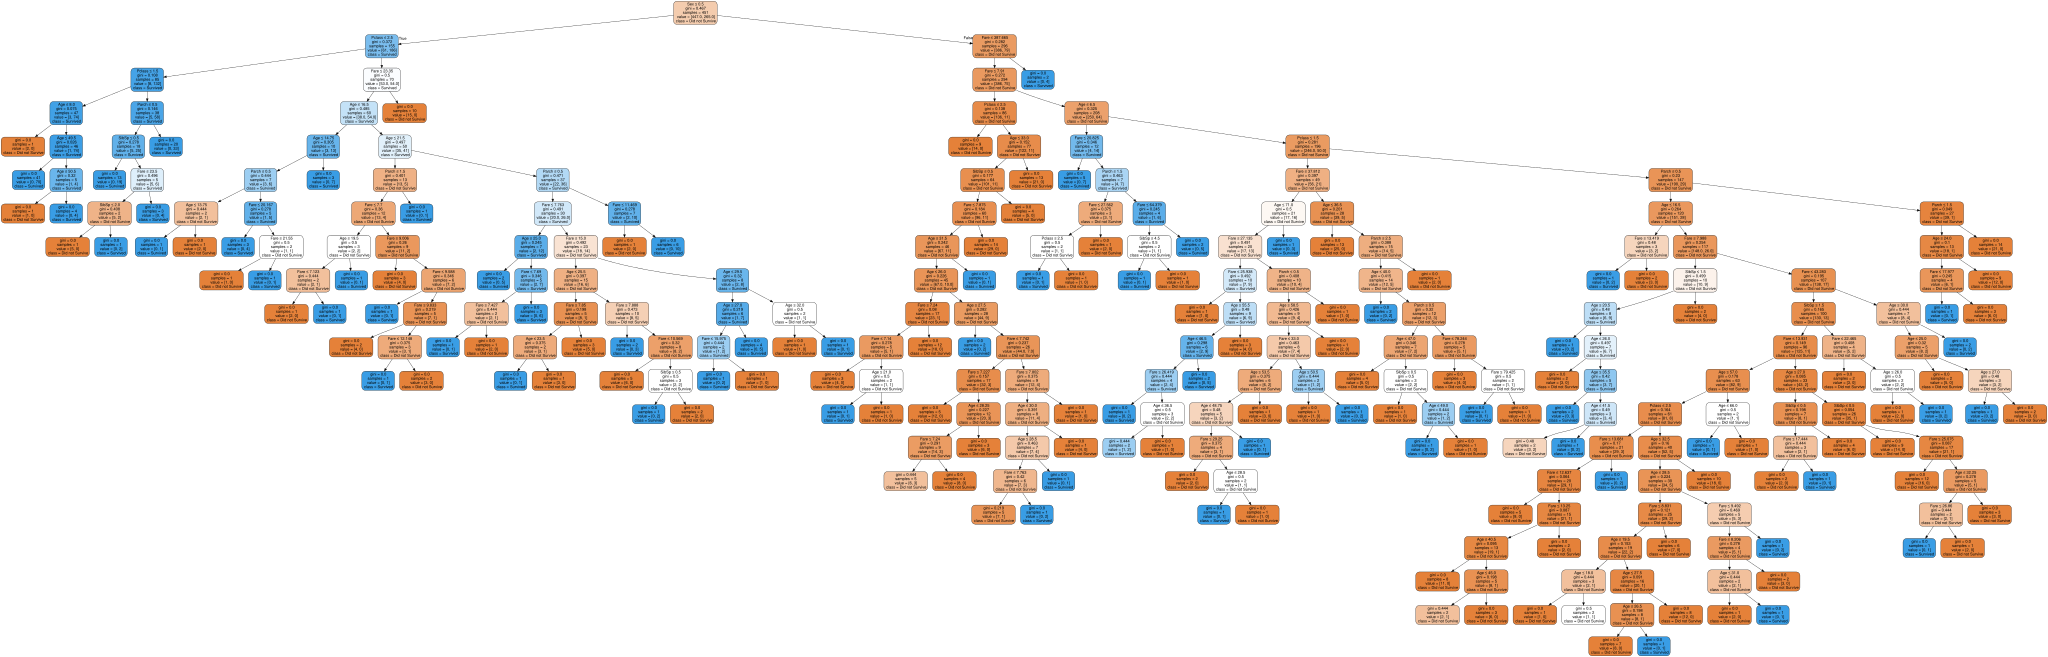

In [25]:
from sklearn.tree import export_graphviz
import graphviz

# Select one tree from the Random Forest
estimator = rf_classifier.estimators_[0] # You can choose any tree, here picking the first one

# Get feature names from the training data
feature_names = X_train.columns.tolist()

# Generate dot data
dot_data = export_graphviz(estimator, out_file=None,
                           feature_names=feature_names,
                           class_names=['Did not Survive', 'Survived'],
                           filled=True, rounded=True,
                           special_characters=True)

# Create a graph from the dot data and display it
graph = graphviz.Source(dot_data)
graph